# Image models: shared patient-safe architecture screening
Three complete epochs per fold, canonical crop sizes, AUC checkpointing and pooled OOF evaluation. Uses the shared benchmark runner.


In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Find the project root (the folder holding pyproject.toml) and make src/ importable.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from melanoma_detection.utils import RANDOM_STATE, get_project_paths, setup_logging
from melanoma_detection import data
from melanoma_detection.evaluation import compare_models, plot_model_comparison
from melanoma_detection.image_model import evaluate_image_model, setup_image_model, train_image_model
from melanoma_detection.preprocessing import image_for_display, image_transforms
from melanoma_detection.utils import load_checkpoint, save_checkpoint
setup_logging()
P = get_project_paths(ROOT)   # edit get_project_paths(ROOT, data_dir=...) if your data lives elsewhere
print("Project root:", P.root)
from melanoma_detection.experiments import ImageExperimentConfig, benchmark_image_models
from melanoma_detection.splitting import load_or_create_patient_folds, assign_splits


Project root: C:\Users\jjk91\OneDrive\Documents\GitHub\ADS2002-Melanoma


## GPU check

This stops with a clear message if PyTorch cannot see your GPU, rather than silently training on the CPU.

In [2]:
import torch
print(torch.__version__, torch.version.cuda, torch.cuda.is_available())

from melanoma_detection.utils import require_gpu

device = require_gpu()          # raises if PyTorch cannot see your GPU
print("PyTorch:", torch.__version__, "| CUDA:", torch.version.cuda, "| GPU:", torch.cuda.get_device_name(0))

Using GPU: NVIDIA GeForce RTX 3070 (8.6 GB)


2.6.0+cu124 12.4 True
PyTorch: 2.6.0+cu124 | CUDA: 12.4 | GPU: NVIDIA GeForce RTX 3070


## Data, transforms and loaders

In [3]:
clean_images = pd.read_pickle(P.clean_images)
split_maps = load_or_create_patient_folds(clean_images, P.results)
preview_images = assign_splits(clean_images, split_maps[0])
PREVIEW_MODEL = "resnet18"
from melanoma_detection.model_registry import get_model_spec
train_transform, eval_transform = image_transforms(model_name=PREVIEW_MODEL)
NUM_WORKERS = 0
datasets, loaders, generator = data.make_loaders(
    preview_images, train_transform, eval_transform, batch_size=8,
    seed=RANDOM_STATE, num_workers=NUM_WORKERS, device=device,
)
images, labels, image_ids = next(iter(loaders["train"]))
size = get_model_spec(PREVIEW_MODEL).input_size
assert images.shape[1:] == (3, size, size)
assert torch.isfinite(images).all()
assert ((labels == 0) | (labels == 1)).all()
print("Preview batch:", tuple(images.shape))


Preview batch: (8, 3, 224, 224)


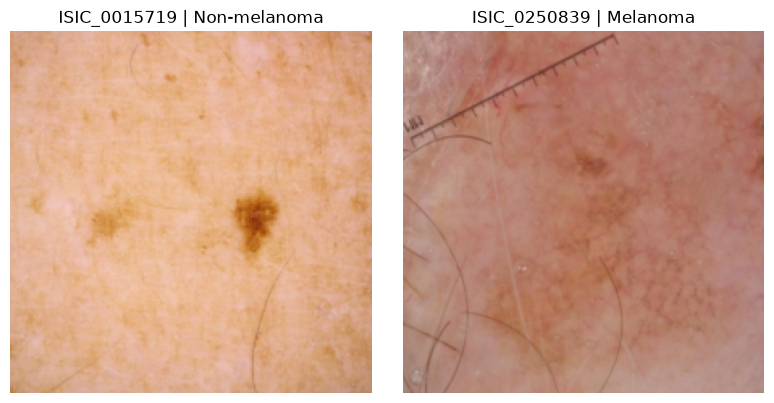

In [4]:
# One augmented training image per class (random flips applied).
rows = datasets["train"].rows
picks = [rows.index[rows["target"].eq(c)][0] for c in (0, 1)]

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, index in zip(axes, picks):
    image, label, name = datasets["train"][index]
    ax.imshow(image_for_display(image))
    ax.set_title(f"{name} | {'Melanoma' if label == 1 else 'Non-melanoma'}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Train all three folds
Epoch 1 trains the head; epochs 2-3 fine-tune the full eligible backbone. BatchNorm parameters and statistics remain frozen. Checkpoints use validation ROC-AUC; threshold metrics use 0.5.


In [5]:
from melanoma_detection.model_registry import MODEL_REGISTRY
benchmark = benchmark_image_models(
    clean_images, P.results / "cross_validation",
    configs=[ImageExperimentConfig(model_name=name, num_workers=NUM_WORKERS) for name in MODEL_REGISTRY],
    split_maps=split_maps, device=device,
    reuse = "never"
)
cv_results = benchmark["results"]
display(benchmark["summary"])


Train melanoma: 87 | non-melanoma: 4482 | raw imbalance ratio: 51.5172 | sqrt pos_weight: 7.1776
Model: resnet18 | Fold: 1 | Input: 224x224 | Weights: ResNet18_Weights.IMAGENET1K_V1 | Device: cuda
Target effective batch: 128 | Microbatch: 128 | Accumulation: 1 | Effective batch: 128
Epoch 1 trainable parameters: 513
NEW BEST CHECKPOINT: ROC-AUC 0.6402
NEW BEST RECALL-90 CHECKPOINT: specificity 0.1756 | threshold 0.095181122
Epoch 1/3 [head warmup] | ROC-AUC 0.6402 | AP 0.0648 | sensitivity 0.000 | specificity 1.000 | balanced accuracy 0.500 | TP 0 FN 40 TN 2096 FP 0 | train loss 0.4724 | val loss 0.3943 | LR backbone 1.00e-04 head 1.00e-03 | Train 26.01s | Val 11.76s | Epoch 37.93s | Total 37.93s
  Fixed-threshold metrics above use 0.5 | Validation recall target >=90%: threshold 0.095181122 | sensitivity 0.925 | specificity 0.176 | TP 37 FN 3 TN 368 FP 1728
Epoch 2+ trainable parameters: 11,167,425
NEW BEST CHECKPOINT: ROC-AUC 0.8320
NEW BEST RECALL-90 CHECKPOINT: specificity 0.6923 | 

,model,weight_enum,input_size,parameter_count,trainable_parameters_epoch1,trainable_parameters_full,device,microbatch_size,accumulation_steps,effective_batch_size,...,pooled_oof_average_precision,pooled_oof_sensitivity,pooled_oof_specificity,pooled_oof_balanced_accuracy,pooled_oof_tn,pooled_oof_fp,pooled_oof_fn,pooled_oof_tp,total_seconds,mean_seconds_per_epoch
4,efficientnet_b3,EfficientNet_B3_Weights.IMAGENET1K_V1,300,10697769,1537,10610473,cuda,64,2,128,...,0.088701,0.062992,0.994831,0.528912,6544,34,119,8,1998.257795,199.578292
7,convnext_tiny,ConvNeXt_Tiny_Weights.IMAGENET1K_V1,224,27820897,2305,27820897,cuda,128,1,128,...,0.077567,0.031496,0.997416,0.514456,6561,17,123,4,509.661470,51.401943
2,resnet50,ResNet50_Weights.IMAGENET1K_V2,224,23510081,2049,23456961,cuda,128,1,128,...,0.070933,0.039370,0.995895,0.517633,6551,27,122,5,382.971074,38.065540
3,efficientnet_b0,EfficientNet_B0_Weights.IMAGENET1K_V1,224,4008829,1281,3966813,cuda,128,1,128,...,0.101325,0.133858,0.988142,0.561000,6500,78,110,17,370.392560,36.753721
6,densenet121,DenseNet121_Weights.IMAGENET1K_V1,224,6954881,1025,6871233,cuda,128,1,128,...,0.070263,0.047244,0.993919,0.520582,6538,40,121,6,640.676765,63.803431
0,resnet18,ResNet18_Weights.IMAGENET1K_V1,224,11177025,513,11167425,cuda,128,1,128,...,0.060012,0.039370,0.996199,0.517785,6553,25,122,5,358.826470,35.579135
1,resnet34,ResNet34_Weights.IMAGENET1K_V1,224,21285185,513,21268161,cuda,128,1,128,...,0.061921,0.007874,0.999088,0.503481,6572,6,126,1,366.196457,36.351808
5,efficientnet_b4,EfficientNet_B4_Weights.IMAGENET1K_V1,380,17550409,1793,17425209,cuda,32,4,128,...,0.059493,0.000000,1.000000,0.500000,6578,0,127,0,2545.886033,260.478278


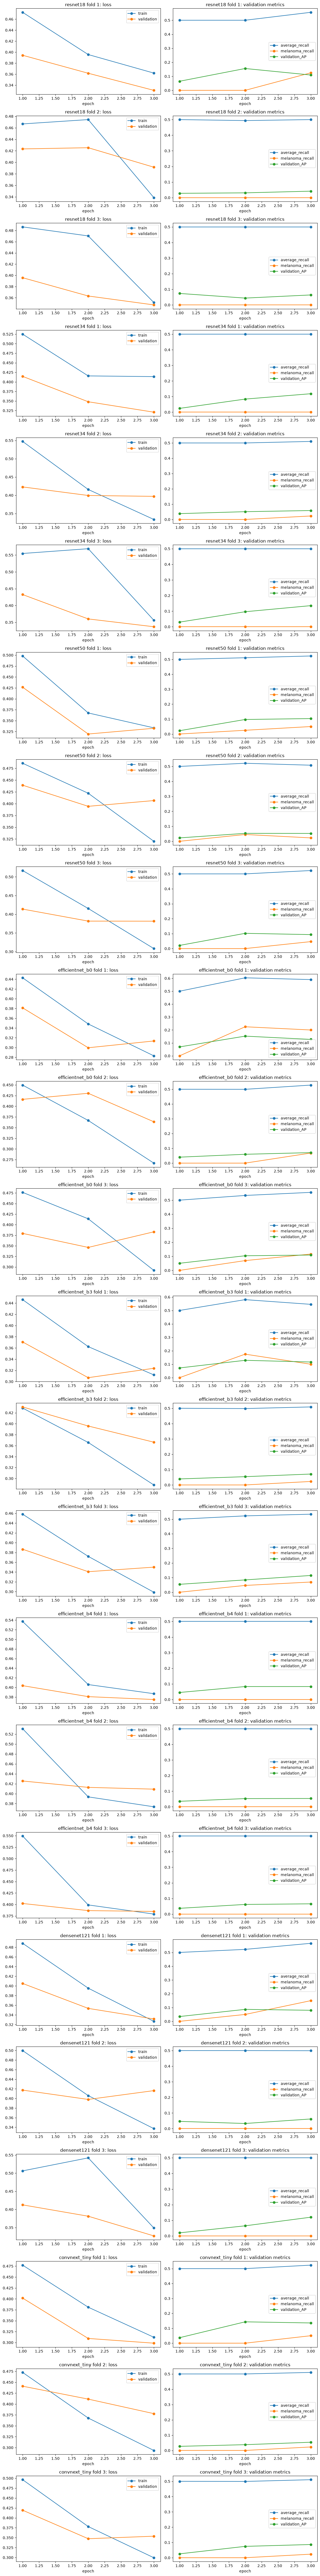

In [6]:
trained = {
    f"{name}_fold_{fold}": {"history": history, "label": f"{name} fold {fold}"}
    for name, result in cv_results.items() for fold, history in result["histories"].items()
}
fig, axes = plt.subplots(len(trained), 2, figsize=(12, 4 * len(trained)), squeeze=False)
for row, info in zip(axes, trained.values()):
    h = info["history"]
    row[0].plot(h["epoch"], h["train_loss"], marker="o", label="train")
    row[0].plot(h["epoch"], h["validation_loss"], marker="o", label="validation")
    row[0].set(title=f"{info['label']}: loss", xlabel="epoch")
    row[0].legend()
    for column in ["average_recall", "melanoma_recall", "validation_AP"]:
        row[1].plot(h["epoch"], h[column], marker="o", label=column)
    row[1].set(title=f"{info['label']}: validation metrics", xlabel="epoch")
    row[1].legend()
plt.tight_layout()
plt.show()

## Cross-validation results
Pooled OOF ROC-AUC is the primary comparison; fold mean/std are separately labelled. Every image has one OOF prediction and each patient belongs to one validation fold. Threshold metrics use 0.5. Validation selects checkpoints, so these are development results.


In [7]:
validation_predictions = {name: result["predictions"] for name, result in cv_results.items()}
for name, result in cv_results.items():
    print(name)
    display(result["fold_metrics"].round(4))
    display(result["summary"].round(4))


resnet18


,roc_auc,average_precision,sensitivity,specificity,balanced_accuracy,tn,fp,fn,tp,ROC-AUC,best_epoch,total_seconds,reused
fold,,,,,,,,,,,,,
1,0.8417,0.1093,0.125,0.9881,0.5565,2071,25,35,5,0.8417,3,118.2233,False
2,0.7345,0.0414,0.000,1.0000,0.5000,2183,0,44,0,0.7345,3,113.9937,False
3,0.8051,0.0638,0.000,1.0000,0.5000,2299,0,43,0,0.8051,3,124.9948,False


,model,weight_enum,input_size,parameter_count,trainable_parameters_epoch1,trainable_parameters_full,device,microbatch_size,accumulation_steps,effective_batch_size,...,pooled_oof_average_precision,pooled_oof_sensitivity,pooled_oof_specificity,pooled_oof_balanced_accuracy,pooled_oof_tn,pooled_oof_fp,pooled_oof_fn,pooled_oof_tp,total_seconds,mean_seconds_per_epoch
0,resnet18,ResNet18_Weights.IMAGENET1K_V1,224,11177025,513,11167425,cuda,128,1,128,...,0.06,0.0394,0.9962,0.5178,6553,25,122,5,358.8265,35.5791


resnet34


,roc_auc,average_precision,sensitivity,specificity,balanced_accuracy,tn,fp,fn,tp,ROC-AUC,best_epoch,total_seconds,reused
fold,,,,,,,,,,,,,
1,0.8513,0.1183,0.0000,1.0000,0.50,2096,0,40,0,0.8513,3,125.4563,False
2,0.7686,0.0583,0.0227,0.9973,0.51,2177,6,43,1,0.7686,3,119.9641,False
3,0.8089,0.1352,0.0000,1.0000,0.50,2299,0,43,0,0.8089,3,119.3386,False


...

,roc_auc,average_precision,sensitivity,specificity,balanced_accuracy,tn,fp,fn,tp,ROC-AUC,best_epoch,total_seconds,reused
fold,,,,,,,,,,,,,
1,0.8326,0.0802,0.15,0.9823,0.5662,2059,37,34,6,0.8326,3,218.7873,False
2,0.7538,0.0618,0.00,0.9986,0.4993,2180,3,44,0,0.7538,3,210.5854,False
3,0.8231,0.1198,0.00,1.0000,0.5000,2299,0,43,0,0.8231,3,209.1669,False


,model,weight_enum,input_size,parameter_count,trainable_parameters_epoch1,trainable_parameters_full,device,microbatch_size,accumulation_steps,effective_batch_size,...,pooled_oof_average_precision,pooled_oof_sensitivity,pooled_oof_specificity,pooled_oof_balanced_accuracy,pooled_oof_tn,pooled_oof_fp,pooled_oof_fn,pooled_oof_tp,total_seconds,mean_seconds_per_epoch
0,densenet121,DenseNet121_Weights.IMAGENET1K_V1,224,6954881,1025,6871233,cuda,128,1,128,...,0.0703,0.0472,0.9939,0.5206,6538,40,121,6,640.6768,63.8034


convnext_tiny


,roc_auc,average_precision,sensitivity,specificity,balanced_accuracy,tn,fp,fn,tp,ROC-AUC,best_epoch,total_seconds,reused
fold,,,,,,,,,,,,,
1,0.8894,0.1356,0.0500,0.9967,0.5233,2089,7,38,2,0.8894,3,169.5819,False
2,0.7650,0.0537,0.0227,0.9973,0.5100,2177,6,43,1,0.7650,3,169.3506,False
3,0.7970,0.0865,0.0233,0.9983,0.5108,2295,4,42,1,0.7970,3,169.0296,False


,model,weight_enum,input_size,parameter_count,trainable_parameters_epoch1,trainable_parameters_full,device,microbatch_size,accumulation_steps,effective_batch_size,...,pooled_oof_average_precision,pooled_oof_sensitivity,pooled_oof_specificity,pooled_oof_balanced_accuracy,pooled_oof_tn,pooled_oof_fp,pooled_oof_fn,pooled_oof_tp,total_seconds,mean_seconds_per_epoch
0,convnext_tiny,ConvNeXt_Tiny_Weights.IMAGENET1K_V1,224,27820897,2305,27820897,cuda,128,1,128,...,0.0776,0.0315,0.9974,0.5145,6561,17,123,4,509.6615,51.4019


,AP,ROC_AUC,recall,specificity,precision,F1,TN,FP,FN,TP,average_recall
model,,,,,,,,,,,
efficientnet_b0,0.1013,0.8017,0.1339,0.9881,0.1789,0.1532,6500,78,110,17,0.5610
efficientnet_b3,0.0887,0.8253,0.0630,0.9948,0.1905,0.0947,6544,34,119,8,0.5289
convnext_tiny,0.0776,0.8102,0.0315,0.9974,0.1905,0.0541,6561,17,123,4,0.5145
resnet50,0.0709,0.8085,0.0394,0.9959,0.1562,0.0629,6551,27,122,5,0.5176
densenet121,0.0703,0.7998,0.0472,0.9939,0.1304,0.0694,6538,40,121,6,0.5206
resnet34,0.0619,0.7914,0.0079,0.9991,0.1429,0.0149,6572,6,126,1,0.5035
resnet18,0.0600,0.7944,0.0394,0.9962,0.1667,0.0637,6553,25,122,5,0.5178
efficientnet_b4,0.0595,0.7430,0.0000,1.0000,NaN,0.0000,6578,0,127,0,0.5000


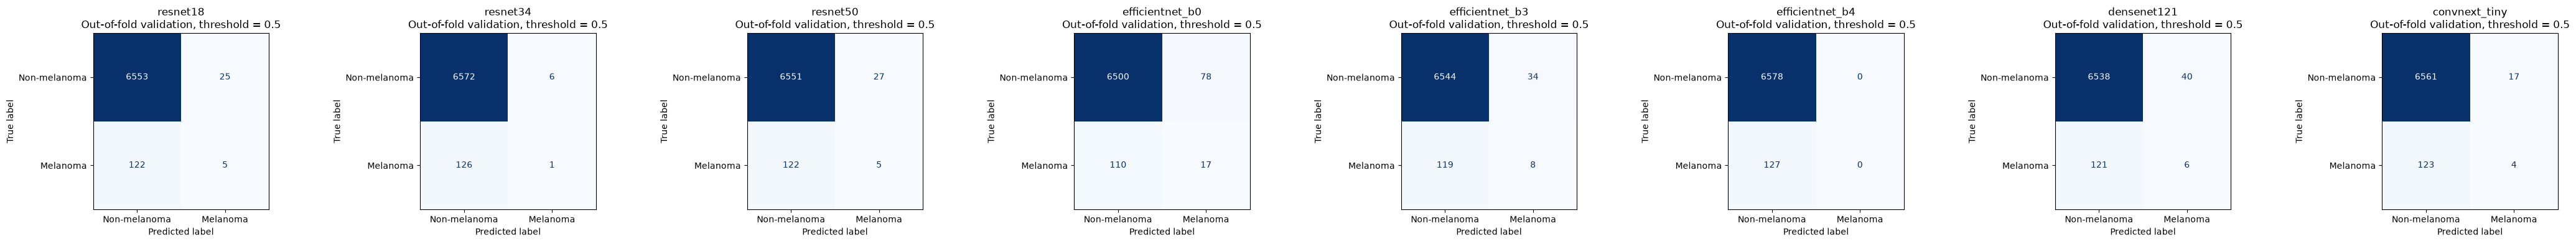

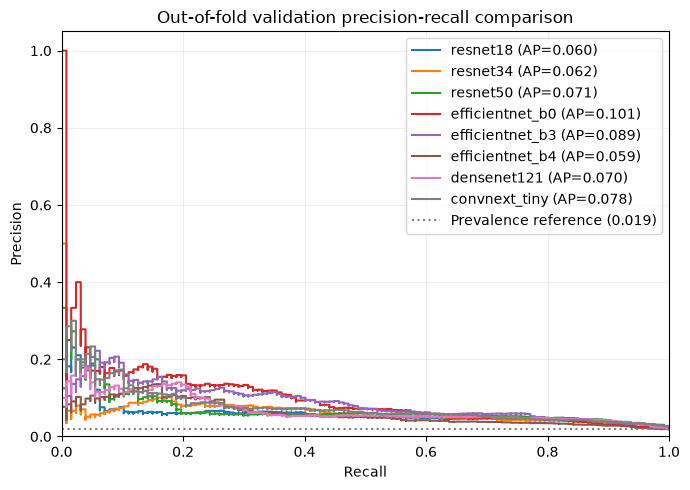

In [8]:
# Side-by-side comparison on the shared score format: image_name, target, score.
comparison_inputs = {
    name: table[["image_name", "target", "melanoma_score"]].rename(columns={"melanoma_score": "score"})
    for name, table in validation_predictions.items()
}
reference = next(iter(comparison_inputs.values())).set_index("image_name")["target"]

display(compare_models(comparison_inputs, reference).round(4))
plot_model_comparison(comparison_inputs, reference, threshold=0.5, title="Out-of-fold validation")
plt.show()